# 04 — Deep-Dive Analysis: Q1, Q2, Q8, Q10
**Week 4 — CadetX Heavy Supplier, Inventory & Warehouse Analytics (Phase 2 kickoff)**

Answers the four locked questions taken into Week 4 (see *Week 4 Sprint Plan*), on the **corrected Week-2 merged datasets**.

| Q | Question | Section |
|---|---|---|
| **Q1** | Net revenue is flat to slightly declining while orders are steady — is it pricing, product mix or demand? | Part 1 |
| **Q2** | South + West make 60.9% of net revenue — market size or under-coverage? | Part 2 |
| **Q8** | Are suppliers really indistinguishable, and is there any basis to select or consolidate? | Part 3 |
| **Q10** | Purchase receipts are ~18× units sold — which side is on the wrong scale? (**do first** — blocks every stock KPI) | Part 4 |

### Definitions used throughout
* **Net revenue** = `line_total` (ex-GST) of **Delivered** orders; Cancelled orders are not revenue.
* **Order year** = year of `order_date`.
* **On-time** (purchase orders) = `delivery_delay_days <= 0` on **Received** POs (same definition as Week 3).

> Every number quoted in the text cells is also produced by a code cell, and the key ones are asserted in the validation report at the end.

> **Revision (25 Oct 2026, final).** Corrections from the team cross-check: (1) Q8 on-time, delay and lead-time tests now use the **purchase order** as the unit of analysis (lines on one PO share one outcome), which changes the Q8 reading from "statistically detectable but negligible" to "not distinguishable"; (2) new section 1.5b tests the 2023→2024 product-mix effect (permutation p = 0.35) and the 2023→2024 revenue change (interval −7.8% to +0.4%); (3) section 1.6 adds the six-year homogeneity (p = 0.27) and trend (p = 0.030) tests for cancellations; (4) Q8 effect sizes added for every test, lead time reported as p < 1e-300, supplier-type overlap on lead time stated; (5) Q2 "₹45M per new customer" marked as an assumption. (6) new section 2.4 adds Ibrahim Khalil's Q2 robustness tests (orders per customer, effect sizes, bootstrap interval for the South + West share, top-customer check, branch link). All checks pass.

## Setup

In [4]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

CANDIDATES = [Path("merged"), Path("data/merged"), Path("../reports/week_02/merged"), Path("../merged")]
DATA_DIR = Path("/Users/macbook/Documents/Heavy-Supplier-Inventory-Warehouse-Analytics/week-02/reports/week_02/merged")
assert (DATA_DIR / "sales_orders_full.csv").exists(), "Merged datasets not found - check the path"
OUT_DIR   = Path("analysis_outputs");   OUT_DIR.mkdir(exist_ok=True)
CHART_DIR = Path("analysis_charts");    CHART_DIR.mkdir(exist_ok=True)
print("Merged datasets :", DATA_DIR.resolve())

def save(df, name, index=False):
    # clean export: counts and rupee totals stay integers; float columns are rounded (no 16-digit floats, no 2.1999999999999997)
    df = df.copy()
    for c in df.select_dtypes(include="float").columns:
        s = df[c].dropna()
        if len(s) and (s == s.round()).all() and s.abs().max() > 1e4: df[c] = df[c].astype("Int64")      # whole numbers (e.g. rupee totals)
        elif "p_value" in c or c.startswith("p_by"): df[c] = df[c].round(6)
        else: df[c] = df[c].round(4 if (len(s) and s.abs().max() < 5) else 2)
    df.to_csv(OUT_DIR / name, index=index); print(f"saved {name} ({len(df)} rows)")
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(CHART_DIR / name, dpi=130, facecolor=fig.get_facecolor()); plt.show(); plt.close(fig); print("saved chart", name)

SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2"
plt.rcParams.update({"figure.facecolor":SURF, "axes.facecolor":SURF, "savefig.facecolor":SURF,
    "text.color":INK, "axes.labelcolor":INK2, "xtick.color":INK2, "ytick.color":INK2, "axes.edgecolor":MUTED,
    "axes.titleweight":"bold", "axes.titlesize":11, "axes.titlelocation":"left", "axes.spines.top":False, "axes.spines.right":False,
    "axes.grid":True, "grid.color":GRID, "grid.linewidth":.8, "axes.axisbelow":True, "legend.frameon":False, "font.size":9.5, "figure.dpi":110})
def figs(nrows=1, ncols=1, size=(11,4.2), **kw):
    return plt.subplots(nrows, ncols, figsize=size, **kw)
def hbar(ax, labels, values, title, fmt="{:,.2f}", color=BLUE, xlabel=None, hi=None):
    y = np.arange(len(labels))[::-1]; cols = [color]*len(labels)
    if hi is not None:
        for h_ in (hi if isinstance(hi, (list,tuple)) else [hi]): cols[h_] = ORANGE
    ax.barh(y, values, color=cols, height=.62); ax.set_yticks(y); ax.set_yticklabels(labels)
    for yi,v in zip(y,values): ax.text(v, yi, "  "+fmt.format(v), va="center", fontsize=8.5, color=INK2)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.margins(x=.18)
    if xlabel: ax.set_xlabel(xlabel)
def sbar(ax, labels, values, title, fmt="{:,.1f}", color=BLUE, hi=None):
    # horizontal bars that may be negative; label sits just beyond the bar end, outside the bar
    y = np.arange(len(labels))[::-1]; cols = [color]*len(labels)
    for h_ in (hi or []): cols[h_] = ORANGE
    ax.barh(y, values, color=cols, height=.62); ax.set_yticks(y); ax.set_yticklabels(labels); ax.axvline(0, color=INK2, lw=.8)
    for yi,v in zip(y,values):
        ax.annotate(fmt.format(v), (v,yi), xytext=(-4 if v<0 else 4,0), textcoords="offset points", ha="right" if v<0 else "left", va="center", fontsize=8.5, color=INK2)
    ax.set_title(title); ax.grid(axis="y", visible=False)
checks = []
def check(name, expected, actual, ok): checks.append((name, expected, actual, "PASS" if ok else "FAIL")); assert ok, name

Merged datasets : /Users/macbook/Documents/Heavy-Supplier-Inventory-Warehouse-Analytics/week-02/reports/week_02/merged


## 0. Load & integrity checks

In [5]:
sales = pd.read_csv(DATA_DIR/"sales_orders_full.csv",   low_memory=False, parse_dates=["order_date","delivery_date"])
po    = pd.read_csv(DATA_DIR/"purchase_orders_full.csv", low_memory=False, parse_dates=["order_date","expected_delivery_date","received_date"])
invl  = pd.read_csv(DATA_DIR/"inventory_with_ledger.csv", low_memory=False)
led   = pd.read_csv(DATA_DIR/"stock_ledger_enriched.csv", low_memory=False, parse_dates=["movement_date"])

check("sales rows (line grain)",  130402, len(sales), len(sales)==130402)
check("unique orders",            20000,  sales.so_id.nunique(), sales.so_id.nunique()==20000)
check("PO rows (line grain)",     155495, len(po), len(po)==155495)
check("inventory pairs",          180,    len(invl), len(invl)==180)
check("ledger rows",              237230, len(led), len(led)==237230)

sales["order_year"] = sales.order_date.dt.year
orders  = sales.drop_duplicates("so_id").copy()
deliv_l = sales[sales.order_status=="Delivered"].copy()          # delivered lines
rcv     = po[po.po_status=="Received"].copy()                    # received PO lines
net_rev = deliv_l.line_total.sum()
check("net revenue matches Week 3 (₹22.96B)", 22.96, round(net_rev/1e9,2), round(net_rev/1e9,2)==22.96)
print(f"Net revenue (delivered, ex-GST): ₹{net_rev/1e9:,.2f}B | orders {len(orders):,} | delivered lines {len(deliv_l):,} | received PO lines {len(rcv):,}")

Net revenue (delivered, ex-GST): ₹22.96B | orders 20,000 | delivered lines 117,656 | received PO lines 140,077


# Part 1 — Q1: Why is revenue flat to slightly declining despite steady order volume?

**Approach (from the sprint plan):** (a) test for a price effect, (b) split the year-on-year change into *orders placed*, *cancellation rate*, *product mix* and *basket size*, (c) find where the mix effect comes from, (d) test whether the 2024 cancellation increase is real and where it sits.

## 1.1 The yearly picture

In [6]:
yr = pd.DataFrame({
    "placed":    orders.groupby("order_year").so_id.nunique(),
    "delivered": orders[orders.order_status=="Delivered"].groupby("order_year").so_id.nunique(),
    "units":     deliv_l.groupby("order_year").quantity.sum(),
    "net_revenue": deliv_l.groupby("order_year").line_total.sum()})
yr["cancelled"]       = yr.placed - yr.delivered
yr["cancel_rate_pct"] = yr.cancelled/yr.placed*100
yr["aov_M"]           = yr.net_revenue/yr.delivered/1e6
yr["units_per_order"] = yr.units/yr.delivered
yr["rev_per_unit"]    = yr.net_revenue/yr.units
check("yearly net revenue sums to total", 0, round(yr.net_revenue.sum()-net_rev,2), abs(yr.net_revenue.sum()-net_rev)<1)
save(yr.reset_index(), "q1_yearly_summary.csv")
yr.assign(net_revenue_B=yr.net_revenue/1e9).drop(columns="net_revenue").round(2)

saved q1_yearly_summary.csv (6 rows)


,placed,delivered,units,cancelled,cancel_rate_pct,aov_M,units_per_order,rev_per_unit,net_revenue_B
order_year,,,,,,,,,
2019,3336,3031,207925,305,9.14,1.28,68.60,"18,612.56",3.87
2020,3358,3038,212007,320,9.53,1.29,69.79,"18,478.31",3.92
2021,3365,3038,208269,327,9.72,1.27,68.55,"18,497.61",3.85
2022,3279,2948,202242,331,10.09,1.29,68.60,"18,869.91",3.82
2023,3346,3022,204638,324,9.68,1.27,67.72,"18,689.96",3.82
2024,3316,2956,199858,360,10.86,1.24,67.61,"18,403.04",3.68


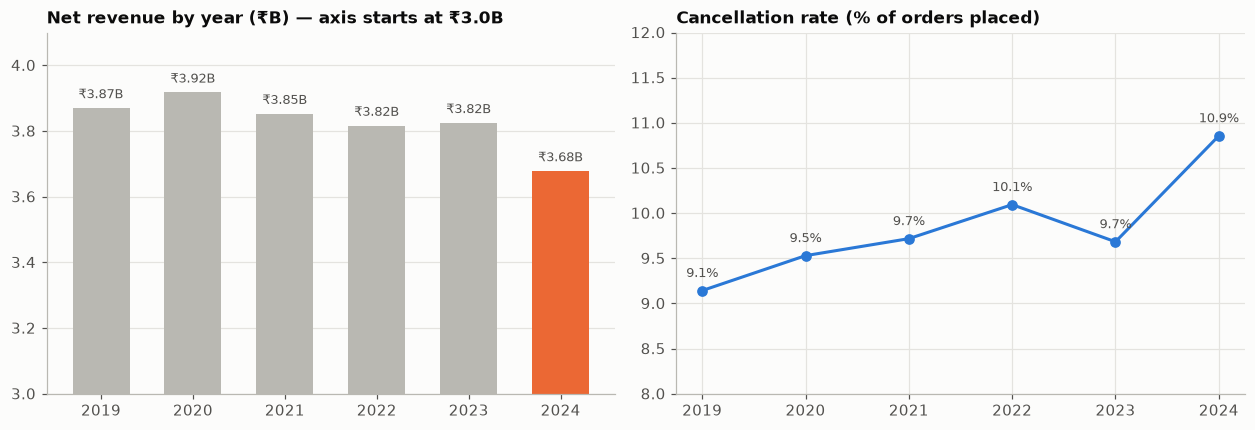

saved chart q1_01_revenue_and_cancellation_by_year.png


In [7]:
fig, axs = figs(1,2,size=(11.5,4))
axs[0].bar(yr.index.astype(str), yr.net_revenue/1e9, color=[MUTED]*5+[ORANGE], width=.62)
for x_,v in zip(yr.index.astype(str), yr.net_revenue/1e9): axs[0].text(x_, v+.03, f"₹{v:.2f}B", ha="center", fontsize=8.5, color=INK2)
axs[0].set_ylim(3.0,4.1); axs[0].set_title("Net revenue by year (₹B) — axis starts at ₹3.0B"); axs[0].grid(axis="x", visible=False)
axs[1].plot(yr.index, yr.cancel_rate_pct, color=BLUE, marker="o", lw=2)
for x_,v in zip(yr.index, yr.cancel_rate_pct): axs[1].text(x_, v+.15, f"{v:.1f}%", ha="center", fontsize=8.5, color=INK2)
axs[1].set_ylim(8,12); axs[1].set_title("Cancellation rate (% of orders placed)"); axs[1].set_xticks(yr.index)
savefig(fig, "q1_01_revenue_and_cancellation_by_year.png")

## 1.2 Is there a price effect? (price test)

In [8]:
# 1) every product has exactly one unit_price on the order lines, in all six years
ppp = sales.groupby("product_id").unit_price.nunique()
ppy = sales.groupby(["product_id","order_year"]).unit_price.nunique()
# 2) and that price equals the product master price
master = po.groupby("product_id").unit_price.agg(["nunique","first"])
chk = sales.merge(master["first"].rename("master_price"), left_on="product_id", right_index=True)
n_diff = int((chk.unit_price.round(2) != chk.master_price.round(2)).sum())
print(f"prices per product on order lines : min {ppp.min()}, max {ppp.max()}  (30 products)")
print(f"products with >1 price in any year: {int((ppy>1).sum())}")
print(f"order lines whose price != master : {n_diff:,} of {len(sales):,}")
check("each product has exactly one unit_price", 1, int(ppp.max()), ppp.max()==1 and ppp.min()==1)
check("order-line price == product master price", 0, n_diff, n_diff==0)

prices per product on order lines : min 1, max 1  (30 products)
products with >1 price in any year: 0
order lines whose price != master : 0 of 130,402


**Reading:** all 130,402 order lines carry the product-master price, one price per product for the whole 2019–2024 period. The dataset is a **snapshot of a single price list**, not a record of prices actually charged over time. The price effect is therefore *exactly zero by construction* — pricing **cannot be tested** with this data, and the revenue drift must come from volume, cancellations and mix. This is a data limitation, not evidence that prices were frozen.

## 1.3 Decomposing the change in net revenue
Net revenue is written as a product of four factors:

`Revenue = Orders placed × (1 − cancellation rate) × Units per delivered order × Revenue per unit`

| Factor | Effect name | Meaning |
|---|---|---|
| Orders placed | **Placed** | demand in number of orders |
| Delivered share | **Cancellation** | share of placed orders that were delivered |
| Units per delivered order | **Basket size** | how many units a delivered order contains |
| Revenue per unit | **Product mix** | average ₹ per unit sold — moves only through *which* products are sold, because price is fixed |

The split uses the **log-mean (LMDI) method**, which is exact (the four effects add to the total change with no residual). Because decompositions can depend on the order of the steps, section 1.4 re-runs it with every possible ordering.

In [9]:
t = pd.DataFrame({"N": yr.placed, "D": yr.delivered, "Q": yr.units, "R": yr.net_revenue})
FACT = {"Placed": lambda t: t.N, "Cancellation": lambda t: t.D/t.N, "Basket size": lambda t: t.Q/t.D, "Product mix": lambda t: t.R/t.Q}
F = pd.DataFrame({k: f(t) for k,f in FACT.items()})
check("factors multiply back to revenue", 0, float(np.abs(F.prod(axis=1)-t.R).max()), np.allclose(F.prod(axis=1), t.R))

def lmdi(a, b):
    dR = t.R[b]-t.R[a]; L = dR/(np.log(t.R[b])-np.log(t.R[a]))
    return {k: L*np.log(F[k][b]/F[k][a]) for k in F.columns}

def decomp_table():
    rows = []
    for a,b in [(y,y+1) for y in range(2019,2024)] + [(2019,2024)]:
        e = lmdi(a,b); dR = t.R[b]-t.R[a]
        rows.append({"from":a, "to":b, "change_M": dR/1e6, **{f"{k}_M": v/1e6 for k,v in e.items()}, **{f"{k}_%": v/dR*100 for k,v in e.items()}})
    return pd.DataFrame(rows)
dec = decomp_table()
for a,b in [(2023,2024),(2019,2024)]:
    e = lmdi(a,b); check(f"effects add to total change {a}-{b}", 0, round(sum(e.values())-(t.R[b]-t.R[a]),2), abs(sum(e.values())-(t.R[b]-t.R[a]))<1)
save(dec, "q1_decomposition_by_period.csv")
dec.round(1)

saved q1_decomposition_by_period.csv (6 rows)


,from,to,change_M,Placed_M,Cancellation_M,Basket size_M,Product mix_M,Placed_%,Cancellation_%,Basket size_%,Product mix_%
0,2019,2020,47.50,25.60,-16.60,66.70,-28.20,53.90,-35.00,140.40,-59.30
1,2020,2021,-65.10,8.10,-8.10,-69.10,4.10,-12.40,12.40,106.20,-6.20
2,2021,2022,-36.20,-99.30,-16.00,2.70,76.40,274.30,44.30,-7.50,-211.10
3,2022,2023,8.40,77.30,17.40,-49.70,-36.60,921.40,207.90,-592.80,-436.50
4,2023,2024,-146.70,-33.80,-49.00,-5.80,-58.00,23.00,33.40,4.00,39.60
5,2019,2024,-192.00,-22.70,-71.90,-54.80,-42.70,11.80,37.40,28.50,22.20


Change 2023 → 2024: ₹-146.7M  (-3.84%)
  Placed        ₹   -33.8M    23.0% of the fall
  Cancellation  ₹   -49.0M    33.4% of the fall
  Basket size   ₹    -5.8M     4.0% of the fall
  Product mix   ₹   -58.0M    39.6% of the fall

  Order volume (placed + cancellation): 56.5%   |   Value per delivered order (basket + mix): 43.5%


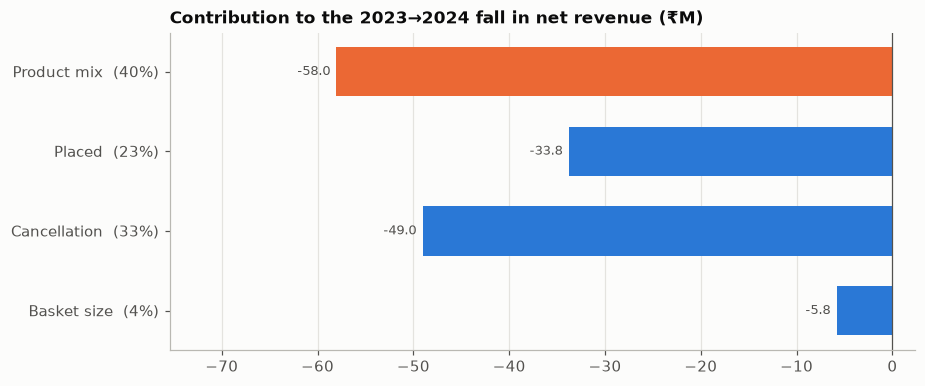

saved chart q1_02_decomposition_2023_2024.png


In [10]:
a,b = 2023, 2024
e = lmdi(a,b); dR = t.R[b]-t.R[a]
print(f"Change {a} → {b}: ₹{dR/1e6:,.1f}M  ({dR/t.R[a]*100:+.2f}%)")
share = {k: v/dR*100 for k,v in e.items()}
for k,v in e.items(): print(f"  {k:<13} ₹{v/1e6:>8,.1f}M   {share[k]:5.1f}% of the fall")
print(f"\n  Order volume (placed + cancellation): {share['Placed']+share['Cancellation']:.1f}%   |   Value per delivered order (basket + mix): {share['Basket size']+share['Product mix']:.1f}%")
check("2023→2024 fall is ₹146.7M", 146.7, round(-dR/1e6,1), round(-dR/1e6,1)==146.7)
check("shares sum to 100%", 100, round(sum(share.values()),6), abs(sum(share.values())-100)<1e-6)

order = ["Product mix","Placed","Cancellation","Basket size"]
fig, ax = figs(size=(8.5,3.6))
vals = [e[k]/1e6 for k in order]
sbar(ax, [f"{k}  ({share[k]:.0f}%)" for k in order], vals, "Contribution to the 2023→2024 fall in net revenue (₹M)", hi=[0])
ax.set_xlim(min(vals)*1.3, 0.04*abs(min(vals)))
savefig(fig, "q1_02_decomposition_2023_2024.png")

## 1.4 Does the answer depend on the order of the decomposition?

In [11]:
def sequential(a, b, order):
    cur = {k: F[k][a] for k in F.columns}; prev = np.prod(list(cur.values())); out = {}
    for k in order:
        cur[k] = F[k][b]; new = np.prod(list(cur.values())); out[k] = new-prev; prev = new
    return out
res = []
for perm in itertools.permutations(F.columns):
    s_ = sequential(2023, 2024, perm); res.append({k: s_[k]/dR*100 for k in F.columns})
sens = pd.DataFrame(res)
rng = pd.DataFrame({"LMDI (used)": pd.Series(share), "lowest over 24 orderings": sens.min(), "highest over 24 orderings": sens.max()}).round(1)
save(rng.reset_index().rename(columns={"index":"effect"}), "q1_decomposition_order_sensitivity.csv")
print("Share of the 2023→2024 fall (%), LMDI vs the range over all 24 step-orders:"); rng

saved q1_decomposition_order_sensitivity.csv (4 rows)
Share of the 2023→2024 fall (%), LMDI vs the range over all 24 step-orders:


,LMDI (used),lowest over 24 orderings,highest over 24 orderings
Placed,23.00,22.70,23.40
Cancellation,33.40,33.00,33.90
Basket size,4.00,3.90,4.00
Product mix,39.60,39.10,40.00


**Reading:** the effects are stable in *rank*: product mix and the cancellation effect are the two largest; order volume (placed + cancellation) explains a bit over half of the fall, value per delivered order (mix + basket) the rest. Across all 24 possible step-orders each share moves by **less than one percentage point** (e.g. product mix 39.1–40.0%, cancellation 33.0–33.9%), so the split is robust. Still quote the shares as "about" and name the method (LMDI). Stable size does not mean statistically real: see 1.5b for the significance tests.

## 1.5 Where does the product-mix effect come from?

saved q1_category_change_2023_2024.csv (15 rows)
product_name
Engine Block EB-600   -71.30
Swing Motor SWM-350   -45.20
Turbocharger TB-900   -27.60
Control Valve CV-75    -9.40
...


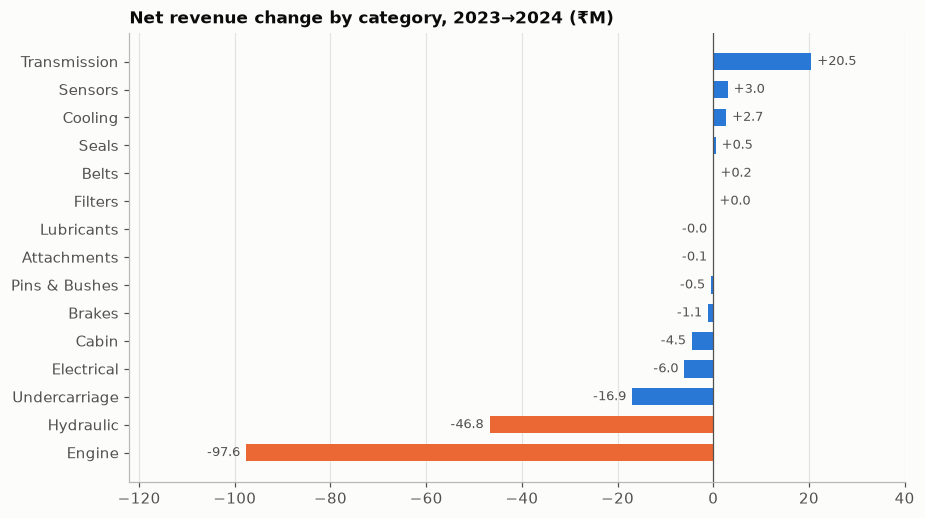

saved chart q1_03_category_change_2023_2024.png


order_year,chg_2023_24_M,share_2023_%,share_2024_%,share_chg_pp
category,,,,
Engine,-97.63,33.61,32.30,-1.31
Hydraulic,-46.75,28.29,28.14,-0.14
Undercarriage,-16.94,13.25,13.31,0.07
Electrical,-6.03,5.09,5.13,0.04
Cabin,-4.47,1.42,1.36,-0.06
Brakes,-1.09,0.43,0.42,-0.01
Pins & Bushes,-0.47,0.21,0.20,-0.00
Attachments,-0.05,0.10,0.11,0.00
Lubricants,-0.04,0.05,0.05,0.00


In [12]:
cat = deliv_l.pivot_table(index="category", columns="order_year", values="line_total", aggfunc="sum")
cat["chg_2023_24_M"] = (cat[2024]-cat[2023])/1e6
cat["share_2023_%"] = cat[2023]/cat[2023].sum()*100; cat["share_2024_%"] = cat[2024]/cat[2024].sum()*100
cat["share_chg_pp"] = cat["share_2024_%"]-cat["share_2023_%"]
cat = cat.sort_values("chg_2023_24_M")
save(cat.reset_index(), "q1_category_change_2023_2024.csv")
top = deliv_l[deliv_l.order_year.isin([2023,2024])].pivot_table(index="product_name", columns="order_year", values="line_total", aggfunc="sum")
top["chg_M"] = (top[2024]-top[2023])/1e6; top = top.sort_values("chg_M")
print(top.chg_M.head(4).round(1).to_string()); print("...")
fig, ax = figs(size=(8.5,4.8))
cc = cat.chg_2023_24_M
sbar(ax, cc.index[::-1], cc.values[::-1], "Net revenue change by category, 2023→2024 (₹M)", fmt="{:+,.1f}", hi=[len(cc)-1, len(cc)-2])
ax.set_xlim(cc.min()*1.25, 40)
savefig(fig, "q1_03_category_change_2023_2024.png")
cat[["chg_2023_24_M","share_2023_%","share_2024_%","share_chg_pp"]].round(2)

**Reading:** the fall is concentrated in **Engine** (−₹97.6M) and **Hydraulic** (−₹46.8M), with Undercarriage (−₹16.9M) third; **Transmission grew** (+₹20.5M) and Cooling and Sensors edged up. Engine's share of revenue fell 1.3 pp while Transmission's rose 1.1 pp. The largest single-product drops are Engine Block EB-600 (−₹71.3M), Swing Motor SWM-350 (−₹45.2M) and Turbocharger TB-900 (−₹27.6M). Because prices are fixed, the "mix" effect is purely a shift in *which products are sold*, not in what they cost.

## 1.5b Are the product-mix effect and the 2023→2024 fall distinguishable from noise?
A split of a change into components says how big each part is, not whether it is more than random variation. Two tests: (1) a **permutation test** on the 2023→2024 mix effect (shuffle the year label across whole orders 5,000 times and recompute the mix effect each time), and (2) a **bootstrap interval** for the 2023→2024 revenue change.

In [13]:
rng = np.random.default_rng(42)
pr_ = deliv_l.groupby("product_id").unit_price.first()
sub2 = deliv_l[deliv_l.order_year.isin([2023, 2024])]
M2 = sub2.pivot_table(index="so_id", columns="product_id", values="quantity", aggfunc="sum", fill_value=0)[pr_.index]
lab2 = sub2.drop_duplicates("so_id").set_index("so_id").loc[M2.index, "order_year"].values
Mv2, pv2 = M2.values.astype(float), pr_.values.astype(float)
def mix_stat(labels):
    q0 = Mv2[labels == 2023].sum(0); q1 = Mv2[labels == 2024].sum(0)
    return float(pv2 @ q1 - q1.sum() / q0.sum() * (pv2 @ q0))
obs_mix = mix_stat(lab2)
perm = np.array([mix_stat(rng.permutation(lab2)) for _ in range(5000)])
p_mix = float((np.abs(perm) >= abs(obs_mix)).mean())
print(f"2023→2024 mix effect = ₹{obs_mix/1e6:,.1f}M; shuffled 95% range [₹{np.percentile(perm,2.5)/1e6:,.1f}M, ₹{np.percentile(perm,97.5)/1e6:,.1f}M]; permutation p = {p_mix:.3f}")
v23 = orders[(orders.order_status=="Delivered") & (orders.order_year==2023)].total_order_value.values
v24 = orders[(orders.order_status=="Delivered") & (orders.order_year==2024)].total_order_value.values
boot = np.array([rng.choice(v24, len(v24)).sum()/rng.choice(v23, len(v23)).sum()-1 for _ in range(5000)])*100
lo_b, hi_b = np.percentile(boot, [2.5, 97.5]); chg = (v24.sum()/v23.sum()-1)*100
print(f"2023→2024 net revenue change = {chg:.2f}%; bootstrap 95% interval [{lo_b:.2f}%, {hi_b:.2f}%]")
sig_q1 = pd.DataFrame([["Product-mix effect 2023→2024 (permutation, 5,000 shuffles)", obs_mix/1e6, p_mix], ["Net revenue change 2023→2024, bootstrap 95% interval low (%)", lo_b, np.nan], ["Net revenue change 2023→2024, bootstrap 95% interval high (%)", hi_b, np.nan]], columns=["test","value","p_value"])
save(sig_q1.round(4), "q1_mix_and_step_significance.csv")
check("2023→2024 mix effect is not distinguishable from noise (p > 0.05)", ">0.05", round(p_mix,3), p_mix>0.05)
check("2023→2024 permutation statistic reproduces the decomposition mix effect (within ₹1M)", 0, round(obs_mix/1e6 - (-57.3),1), abs(obs_mix/1e6 + 57.3) < 1.0)

2023→2024 mix effect = ₹-57.3M; shuffled 95% range [₹-119.4M, ₹118.5M]; permutation p = 0.349
2023→2024 net revenue change = -3.84%; bootstrap 95% interval [-7.79%, 0.38%]
saved q1_mix_and_step_significance.csv (3 rows)


## 1.6 The cancellation increase — is it real, and where is it?

In [14]:
orders["cancelled"] = orders.order_status=="Cancelled"
cy = orders.groupby("order_year").cancelled.agg(["sum","count"]); cy["rate_%"] = cy["sum"]/cy["count"]*100
print(cy.round(2).to_string())
# is 2024 different from the 2019-2023 pool?
a24 = cy.loc[2024]; prior = cy.loc[2019:2023].sum()
tab = np.array([[a24["sum"], a24["count"]-a24["sum"]], [prior["sum"], prior["count"]-prior["sum"]]])
chi2, p_2024, _, _ = stats.chi2_contingency(tab, correction=False)
print(f"\n2024 rate {a24['sum']/a24['count']*100:.2f}% vs 2019-2023 pooled {prior['sum']/prior['count']*100:.2f}%  → chi-square p = {p_2024:.3f}  (2024 was singled out after looking, so this is tentative)")
# the tests that do not depend on picking a year: could all six years share ONE rate, and is there a linear trend?
chi_all = stats.chi2_contingency(np.c_[cy["sum"], cy["count"]-cy["sum"]])
_n, _x, _sc = cy["count"].values, cy["sum"].values, np.arange(len(cy)); _p = _x.sum()/_n.sum()
z_ca = (_sc*(_x-_n*_p)).sum()/np.sqrt(_p*(1-_p)*((_n*_sc**2).sum()-(_n*_sc).sum()**2/_n.sum())); p_ca = 2*(1-stats.norm.cdf(abs(z_ca)))
print(f"six-year homogeneity (chi-square, df 5): p = {chi_all[1]:.3f} | linear trend (Cochran-Armitage): z = {z_ca:.2f}, p = {p_ca:.3f}")
check("six-year cancellation rates are consistent with one constant rate (p > 0.05)", ">0.05", round(chi_all[1],3), chi_all[1]>0.05)
# does cancellation depend on any order attribute?
rows = []
for col in ["customer_region","branch_region","sales_channel","customer_type","payment_terms"]:
    ct = pd.crosstab(orders[col], orders.cancelled); c2, p, _, _ = stats.chi2_contingency(ct)
    rate = ct[True]/ct.sum(axis=1)*100
    rows.append({"attribute": col, "lowest_rate_%": rate.min(), "highest_rate_%": rate.max(), "chi2_p_value": p})
seg = pd.DataFrame(rows); save(seg, "q1_cancellation_by_attribute.csv"); seg.round(3)

            sum  count  rate_%
order_year                    
2019        305   3336    9.14
2020        320   3358    9.53
2021        327   3365    9.72
2022        331   3279   10.09
2023        324   3346    9.68
2024        360   3316   10.86

2024 rate 10.86% vs 2019-2023 pooled 9.63%  → chi-square p = 0.031  (2024 was singled out after looking, so this is tentative)
six-year homogeneity (chi-square, df 5): p = 0.265 | linear trend (Cochran-Armitage): z = 2.18, p = 0.030
saved q1_cancellation_by_attribute.csv (5 rows)


,attribute,lowest_rate_%,highest_rate_%,chi2_p_value
0,customer_region,9.12,10.37,0.44
1,branch_region,9.18,10.04,0.63
2,sales_channel,9.69,10.11,0.89
3,customer_type,9.54,10.46,0.59
4,payment_terms,9.54,10.23,0.78


In [15]:
# is there ANY field in the merged data that records WHY an order was cancelled?
reason_like = {n: [c for c in df.columns if any(k in c.lower() for k in ("reason","remark","comment","note","cause"))]
               for n,df in {"sales_orders_full":sales,"purchase_orders_full":po,"inventory_with_ledger":invl,"stock_ledger_enriched":led}.items()}
print(reason_like)
check("no cancellation-reason field in the merged data", 0, sum(len(v) for v in reason_like.values()), sum(len(v) for v in reason_like.values())==0)

{'sales_orders_full': [], 'purchase_orders_full': [], 'inventory_with_ledger': [], 'stock_ledger_enriched': []}


**Reading:**
* The rate is not a steady climb (9.1 → 9.5 → 9.7 → 10.1 → 9.7 → **10.9**%); 2024 is a jump after a dip. 2024 (10.86%) is higher than the 2019–2023 pool (9.63%) with p = 0.031, but 2024 was singled out after looking at the data, so that p-value is tentative.
* The tests that do not depend on picking a year say the evidence is **weak**: the six yearly rates are consistent with one constant rate (homogeneity p = 0.27), and only a weak linear trend is detectable (Cochran-Armitage p = 0.030). Describe it as "a rise in 2024 with weak statistical support", not as a proven trend.
* Cancellations are spread **evenly** across regions, branches, channels, customer types and payment terms (all chi-square p-values far above 0.05), so there is no segment to target.
* The data has **no cancellation-reason field** (the raw files were checked too), so *why* orders are cancelled cannot be answered here — it should go to the data owner as an open question.

## 1.7 Q1 — Answer
| Finding | Evidence |
|---|---|
| **Price is not a driver — and cannot be tested.** The data is a single price list. | 1 price per product, 0 lines differ from the master |
| **2023→2024: net revenue fell ₹146.7M (−3.8%).** The 95% interval for this change is −7.8% to +0.4%, so it cannot be distinguished from no change. | Sections 1.3, 1.5b |
| **About 57% is order volume** — fewer orders placed (~23%) and a higher cancellation rate (~33–34%). | LMDI split; step-order range in 1.4 |
| **About 43% is value per delivered order** — mostly product mix (~40%, Engine & Hydraulic down), basket size only ~4%. **Product mix is the largest component but is not distinguishable from noise** (permutation p = 0.35; its year-by-year sign flips). | 1.3, 1.5, 1.5b |
| **Cancellations are evenly spread and unexplained; the rise has weak support** (six-year homogeneity p = 0.27, trend p = 0.030). | 1.6 |
| **Caveat for the write-up:** quote shares as "about", name the method, and state that pricing is untestable. | |

# Part 2 — Q2: Is the regional concentration market size or under-coverage?

**Approach:** separate *how many customers* a region has from *how much each customer buys*. If revenue per customer is the same everywhere, the gap is entirely the size of the customer base; then check whether branch presence explains it.

## 2.1 Regional profile (Delivered orders, by customer region)

In [16]:
cust = deliv_l.groupby("customer_region").agg(net_revenue=("line_total","sum"), orders=("so_id","nunique"), customers=("customer_id","nunique"))
cust["revenue_share_%"]  = cust.net_revenue/cust.net_revenue.sum()*100
cust["customer_share_%"] = cust.customers/cust.customers.sum()*100
cust["orders_per_customer"] = cust.orders/cust.customers
cust["rev_per_customer_M"]  = cust.net_revenue/cust.customers/1e6
cust["aov_M"]               = cust.net_revenue/cust.orders/1e6
cust = cust.sort_values("net_revenue", ascending=False)
sw = cust.loc[["South","West"], "revenue_share_%"].sum()
check("customers across regions = all customers", 500, int(cust.customers.sum()), cust.customers.sum()==500)
check("South + West share is 60.9%", 60.9, round(sw,1), round(sw,1)==60.9)
prof = cust.reset_index().rename(columns={"net_revenue":"net_revenue_inr", "revenue_share_%":"revenue_share_pct", "customer_share_%":"customer_share_pct",
                                          "rev_per_customer_M":"rev_per_customer_inr_M", "aov_M":"aov_inr_M"})
prof = prof.astype({"net_revenue_inr":"int64", "orders":"int64", "customers":"int64"})                   # whole numbers stay integers
for c_ in ["revenue_share_pct","customer_share_pct","orders_per_customer","rev_per_customer_inr_M","aov_inr_M"]: prof[c_] = prof[c_].round(2)   # one precision for every decimal column
prof.to_csv(OUT_DIR/"q2_regional_profile.csv", index=False, float_format="%.2f"); print(f"saved q2_regional_profile.csv ({len(prof)} rows)")   # always 2 decimals, e.g. 31.60 not 31.6
print(f"South + West = {sw:.1f}% of net revenue and {cust.loc[['South','West'],'customer_share_%'].sum():.1f}% of customers")
cust.assign(net_revenue_B=cust.net_revenue/1e9).drop(columns="net_revenue").round(2)

saved q2_regional_profile.csv (6 rows)
South + West = 60.9% of net revenue and 61.8% of customers


,orders,customers,revenue_share_%,customer_share_%,orders_per_customer,rev_per_customer_M,aov_M,net_revenue_B
customer_region,,,,,,,,
South,5722,158,31.63,31.60,36.22,45.96,1.27,7.26
West,5335,151,29.32,30.20,35.33,44.57,1.26,6.73
East,3161,87,17.65,17.40,36.33,46.57,1.28,4.05
North,3029,82,17.15,16.40,36.94,48.03,1.30,3.94
Central,406,11,2.19,2.20,36.91,45.62,1.24,0.50
North East,380,11,2.07,2.20,34.55,43.14,1.25,0.47


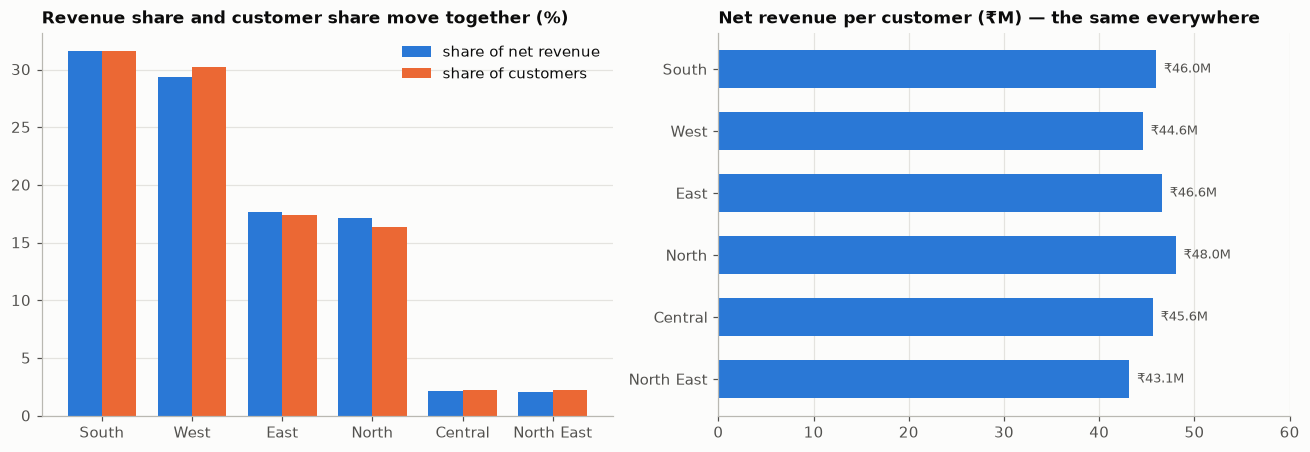

saved chart q2_01_revenue_vs_customers_by_region.png


In [17]:
fig, axs = figs(1,2,size=(12,4.2))
x = np.arange(len(cust)); w = .38
axs[0].bar(x-w/2, cust["revenue_share_%"], w, color=BLUE, label="share of net revenue")
axs[0].bar(x+w/2, cust["customer_share_%"], w, color=ORANGE, label="share of customers")
axs[0].set_xticks(x); axs[0].set_xticklabels(cust.index); axs[0].set_title("Revenue share and customer share move together (%)"); axs[0].legend(loc="upper right"); axs[0].grid(axis="x", visible=False)
hbar(axs[1], cust.index, cust.rev_per_customer_M, "Net revenue per customer (₹M) — the same everywhere", fmt="₹{:.1f}M")
axs[1].set_xlim(0, 60)
savefig(fig, "q2_01_revenue_vs_customers_by_region.png")

## 2.2 Is revenue per customer really the same in every region? (customer-level test)

In [18]:
pc = deliv_l.groupby(["customer_id","customer_region"]).line_total.sum().reset_index()
kw = stats.kruskal(*[g.line_total.values for _,g in pc.groupby("customer_region")])
print(f"500 customers; Kruskal-Wallis on revenue per customer across the 6 regions: H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}")
print(pc.groupby("customer_region").line_total.agg(["count","median"]).assign(median=lambda d: d["median"]/1e6).round(1).rename(columns={"median":"median_rev_per_customer_M"}).to_string())

500 customers; Kruskal-Wallis on revenue per customer across the 6 regions: H = 6.34, p = 0.275
                 count  median_rev_per_customer_M
customer_region                                  
Central             11                      42.80
East                87                      45.50
North               82                      47.00
North East          11                      44.90
South              158                      45.60
West               151                      44.20


## 2.3 Branch presence vs where customers are

In [19]:
br = deliv_l.groupby("branch_region").agg(branches=("branch_id","nunique"), net_revenue=("line_total","sum"))
br["revenue_per_branch_B"] = br.net_revenue/br.branches/1e9
print("Branches by region (a branch serves the orders it receives):"); print(br.assign(net_revenue=br.net_revenue/1e9).rename(columns={"net_revenue":"net_revenue_B"}).round(2).to_string())
ct = pd.crosstab(deliv_l.drop_duplicates("so_id").customer_region, deliv_l.drop_duplicates("so_id").branch_region)
served = ct.div(ct.sum(axis=1), axis=0)*100
print("\nShare of each customer region's orders handled by a branch in the SAME region (%):")
same = pd.Series({r: served.loc[r, r] if r in served.columns else 0.0 for r in served.index}, name="served_in_region_%")
print(same.round(1).to_string())
save(ct.reset_index(), "q2_customer_region_vs_branch_region.csv")

Branches by region (a branch serves the orders it receives):
               branches  net_revenue_B  revenue_per_branch_B
branch_region                                               
East                  1           4.34                  4.34
North                 1           3.50                  3.50
South                 2           7.76                  3.88
West                  2           7.36                  3.68

Share of each customer region's orders handled by a branch in the SAME region (%):
Central       0.00
East         76.50
North        73.30
North East    0.00
South        87.70
West         86.50
saved q2_customer_region_vs_branch_region.csv (6 rows)


## 2.4 How strong is the Q2 conclusion? (robustness)
*Added from Ibrahim Khalil's Q2 package (`Q2_Regional_Concentration`), re-run here on the same data; his numbers reproduce exactly.*

Four questions: (1) do **orders per customer** differ by region, (2) are the regional effects **practically** negligible, (3) how **precise** is the 60.9% concentration figure, (4) is it driven by a few **big customers**? Plus a check that customer region and branch region are linked.

In [20]:
pcx = deliv_l.groupby(["customer_id","customer_region"]).agg(revenue=("line_total","sum"), orders=("so_id","nunique")).reset_index()
kw_r = stats.kruskal(*[g.revenue.values for _,g in pcx.groupby("customer_region")])
kw_o = stats.kruskal(*[g.orders.values  for _,g in pcx.groupby("customer_region")])
n_c, k_r = len(pcx), pcx.customer_region.nunique()
eps_r = max((kw_r.statistic-k_r+1)/(n_c-k_r), 0); eps_o = max((kw_o.statistic-k_r+1)/(n_c-k_r), 0)
print(f"Revenue per customer: Kruskal-Wallis p = {kw_r.pvalue:.3f}, epsilon-squared = {eps_r:.4f}")
print(f"Orders per customer : Kruskal-Wallis p = {kw_o.pvalue:.3f}, epsilon-squared = {eps_o:.4f}  (0 = no regional effect)")

# Central + North East customers vs all others: ratio of revenue per customer with a bootstrap interval
small = pcx.customer_region.isin(["Central","North East"]); rng_q2 = np.random.default_rng(42)
a_, b_ = pcx[small].revenue.values, pcx[~small].revenue.values
boot_r = np.array([rng_q2.choice(a_,len(a_)).mean()/rng_q2.choice(b_,len(b_)).mean() for _ in range(5000)])
r_lo, r_hi = np.percentile(boot_r,[2.5,97.5]); ratio_q2 = a_.mean()/b_.mean()
print(f"Central + North East ({len(a_)} customers) vs others ({len(b_)}): revenue per customer ratio {ratio_q2:.2f}, bootstrap 95% interval [{r_lo:.2f}, {r_hi:.2f}]")

# precision of the headline concentration figure
rng2_q2 = np.random.default_rng(42); sw_boot = []
for _ in range(5000):
    s_ = pcx.iloc[rng2_q2.integers(0,n_c,n_c)]
    sw_boot.append(s_[s_.customer_region.isin(["South","West"])].revenue.sum()/s_.revenue.sum()*100)
sw_lo, sw_hi = np.percentile(sw_boot,[2.5,97.5])
print(f"South + West share {sw:.2f}%, bootstrap 95% interval over customers [{sw_lo:.1f}%, {sw_hi:.1f}%]")

# is it driven by a few big customers?
top_ = pcx.sort_values("revenue", ascending=False)
top5_ = top_.head(5).revenue.sum()/pcx.revenue.sum()*100; top1_ = top_.iloc[0].revenue/pcx.revenue.sum()*100
ex5_ = pcx.drop(top_.head(5).index); sw_ex = ex5_[ex5_.customer_region.isin(["South","West"])].revenue.sum()/ex5_.revenue.sum()*100
print(f"Largest customer {top1_:.2f}% of revenue; top 5 together {top5_:.2f}%; South + West share without the top 5: {sw_ex:.2f}%")

# customer region vs branch region (orders)
ord_ = deliv_l.drop_duplicates("so_id"); ctb = pd.crosstab(ord_.customer_region, ord_.branch_region)
chi2_b = stats.chi2_contingency(ctb.values)[0]; cv_b = float(np.sqrt(chi2_b/(ctb.values.sum()*(min(ctb.shape)-1))))
no_branch = sorted(set(["Central","North East"]) - set(ord_.branch_region.unique()))
print(f"Customer region vs branch region: Cramér's V = {cv_b:.2f}; regions with no branch: {no_branch}")

save(pd.DataFrame([["epsilon-squared, revenue per customer",eps_r],["epsilon-squared, orders per customer",eps_o],["South+West revenue share (%)",sw],
    ["South+West share bootstrap low (%)",sw_lo],["South+West share bootstrap high (%)",sw_hi],["largest customer share of revenue (%)",top1_],
    ["top 5 customers share of revenue (%)",top5_],["South+West share without top 5 (%)",sw_ex],
    ["Central+NE vs others revenue/customer ratio",ratio_q2],["ratio bootstrap low",r_lo],["ratio bootstrap high",r_hi],
    ["orders per customer Kruskal-Wallis p",kw_o.pvalue],["customer vs branch region Cramér's V",cv_b]], columns=["measure","value"]).round(4), "q2_robustness.csv")
check("orders per customer does not differ by region (p > 0.05)", ">0.05", round(kw_o.pvalue,3), kw_o.pvalue>0.05)
check("regional effect on revenue per customer is negligible (epsilon-squared < 0.01)", "<0.01", round(eps_r,4), eps_r<0.01)
check("South + West share stays above 55% across the bootstrap interval", ">55", round(sw_lo,1), sw_lo>55)
check("no single customer drives the concentration (largest < 1% of revenue)", "<1", round(top1_,2), top1_<1)
check("removing the top 5 customers moves the South + West share by less than their own revenue share", "<%.2f"%top5_, round(abs(sw_ex-sw),2), abs(sw_ex-sw)<top5_)
check("Central and North East have no branch", True, no_branch, no_branch==["Central","North East"])
check("customer region and branch region are strongly linked (Cramér's V > 0.5)", ">0.5", round(cv_b,2), cv_b>0.5)

Revenue per customer: Kruskal-Wallis p = 0.275, epsilon-squared = 0.0027
Orders per customer : Kruskal-Wallis p = 0.427, epsilon-squared = 0.0000  (0 = no regional effect)
Central + North East (22 customers) vs others (478): revenue per customer ratio 0.97, bootstrap 95% interval [0.88, 1.06]
South + West share 60.95%, bootstrap 95% interval over customers [56.5%, 65.3%]
Largest customer 0.37% of revenue; top 5 together 1.68%; South + West share without the top 5: 61.99%
Customer region vs branch region: Cramér's V = 0.74; regions with no branch: ['Central', 'North East']
saved q2_robustness.csv (13 rows)


**Reading (Ibrahim's Q2 tests):**
* **No regional difference in behaviour.** Revenue per customer (p = 0.275) and orders per customer (p = 0.427) do not differ by region; effect sizes are negligible (ε² 0.003 and 0.000).
* **The 60.9% is not a precise number:** the 95% bootstrap interval over customers is **56.5% to 65.3%** — quote it as "about 61%" and note it stays above 55%.
* **No single customer drives it:** the largest is 0.37% of revenue, the top 5 together 1.68%; without them South + West is 61.99%.
* **Central + North East customers behave like the others** (revenue per customer ratio 0.97, interval 0.88 to 1.06). With only 22 customers, a gap larger than about 12% is ruled out, but a smaller gap **cannot** be excluded.
* **Branch link:** customer region and branch region are strongly linked (Cramér's V = 0.74); Central and North East have no branch.

## 2.5 Q2 — Answer
| Finding | Evidence |
|---|---|
| **The gap is the size of the customer base, not customer behaviour.** South + West hold 60.9% of revenue *and* ~62% of customers. | 2.1 |
| **Every customer is worth about the same everywhere** — ~₹43–48M per customer, 35–37 orders per customer, AOV ₹1.24–1.30M; the Kruskal-Wallis test (2.2) finds no regional difference in revenue per customer. | 2.1, 2.2 |
| **Central and North East have only 11 customers each** (of 500), so they are ~2% of revenue each purely because they have few customers. Their customers buy like the others (ratio 0.97, interval 0.88–1.06; with 22 customers a gap above ~12% is ruled out, a smaller one cannot be excluded). | 2.1, 2.4 |
| **The result is robust.** Effect sizes are negligible (ε² < 0.01); the South + West share is 60.9% with a 95% interval of 56.5–65.3%, so quote "about 61%"; no single customer drives it (largest 0.37%, top 5 = 1.68% of revenue). | 2.4 |
| **Branch count does not explain per-customer value:** regions served by 1 branch (East, North) and by 2 branches (South, West) have the same revenue per customer. | 2.1, 2.3 |
| **There is no branch in Central or North East** — their orders are handled from other regions' branches. | 2.3 |
| **What the data cannot say:** whether Central / North East are *small markets* or *unserved markets*. Equal per-customer value means growth there is a **customer-acquisition** question: if new customers behaved like existing ones (an assumption, not tested), each would be worth ~₹45M over six years. | |
| **Recommendation for the write-up:** present the finding as "concentration = customer-base size"; recommend testing acquisition in Central / North East before adding branches, since the branch count does not explain per-customer value. | |

# Part 3 — Q8: Are suppliers really indistinguishable, and is there any basis to select or consolidate?

**Approach:** compare the 8 suppliers on every available performance dimension — on-time rate, delay, cancellations, unit cost, reliability score and lead time — and, for each, separate **statistical significance** from **practical size**. Delivery outcomes belong to the whole purchase order, so on-time, delay and lead time are tested **per PO** (21,630), not per line: lines on one PO share the same dates, and treating them as independent would inflate the evidence.

## 3.1 Every product is bought from every supplier

In [21]:
cov = po.groupby("product_id").supplier_id.nunique()
check("every product is bought from all 8 suppliers", 8, int(cov.min()), cov.min()==8 and cov.max()==8)
spend = po.groupby("supplier_id").agg(po_lines=("product_id","size"), products=("product_id","nunique"), spend_B=("line_total", lambda s: s.sum()/1e9))
print(f"products: {po.product_id.nunique()} | suppliers: {po.supplier_id.nunique()} | suppliers per product: min {cov.min()}, max {cov.max()}")
spend["spend_share_%"] = spend.spend_B/spend.spend_B.sum()*100
spend.round(2)

products: 30 | suppliers: 8 | suppliers per product: min 8, max 8


,po_lines,products,spend_B,spend_share_%
supplier_id,,,,
SUP0001,19395,30,43.66,12.60
SUP0002,19227,30,41.81,12.06
SUP0003,19411,30,43.66,12.60
SUP0004,19099,30,42.43,12.24
SUP0005,19884,30,44.75,12.91
SUP0006,19740,30,43.24,12.48
SUP0007,19546,30,43.63,12.59
SUP0008,19193,30,43.43,12.53


## 3.2 Supplier scorecard

In [22]:
rcv["on_time"] = rcv.delivery_delay_days<=0
po["cancelled"] = po.po_status=="Cancelled"
hdr = po.drop_duplicates("po_id")          # cancellation is a PO-header status: count POs, not lines (same as Week 3)
rpo = rcv.drop_duplicates("po_id")         # delivery outcomes (on-time, delay, lead time) belong to the whole PO: lines on one PO share the same dates and supplier
check("each received PO has a single supplier", 1, int(rcv.groupby("po_id").supplier_id.nunique().max()), rcv.groupby("po_id").supplier_id.nunique().max()==1)
check("each received PO has a single delivery delay", 1, int(rcv.groupby("po_id").delivery_delay_days.nunique().max()), rcv.groupby("po_id").delivery_delay_days.nunique().max()==1)
cost_idx = rcv.assign(ci=rcv.unit_cost/rcv.groupby("product_id").unit_cost.transform("mean")).groupby("supplier_id").ci.mean()
sc = rpo.groupby(["supplier_id","supplier_name","supplier_type"]).agg(on_time_pct=("on_time", lambda s: s.mean()*100), avg_delay_days=("delivery_delay_days","mean"),
        avg_lead_days=("lead_time_actual_days","mean"), reliability_score=("reliability_score","first"), received_pos=("po_id","size")).reset_index()
sc["received_lines"] = sc.supplier_id.map(rcv.groupby("supplier_id").size())
sc["cancel_rate_pct"] = sc.supplier_id.map(hdr.groupby("supplier_id").cancelled.mean()*100)
sc["unit_cost_index"] = sc.supplier_id.map(cost_idx)
save(sc, "q8_supplier_scorecard.csv"); sc.round(3)

saved q8_supplier_scorecard.csv (8 rows)


,supplier_id,supplier_name,supplier_type,on_time_pct,avg_delay_days,avg_lead_days,reliability_score,received_pos,received_lines,cancel_rate_pct,unit_cost_index
0,SUP0001,Shenzhen OEM Supplies,OEM,84.92,0.50,19.50,5,2653,17490,9.88,1.00
1,SUP0002,Guangzhou Local Vendor Supplies,Local Vendor,84.97,0.52,10.52,5,2635,17227,10.28,1.00
2,SUP0003,Shanghai Distributor Supplies,Distributor,85.02,0.53,16.53,4,2723,17450,10.22,1.00
3,SUP0004,Ningbo Distributor Supplies,Distributor,84.83,0.50,18.50,3,2664,17057,10.18,1.00
4,SUP0005,Tianjin OEM Supplies,OEM,85.33,0.48,28.48,3,2754,17987,9.53,1.00
5,SUP0006,Qingdao Distributor Supplies,Distributor,85.21,0.50,10.50,3,2752,17908,9.41,1.00
6,SUP0007,Suzhou Local Vendor Supplies,Local Vendor,84.67,0.53,12.53,5,2727,17579,9.94,1.00
7,SUP0008,Hangzhou OEM Supplies,OEM,84.20,0.55,26.55,4,2722,17379,9.57,1.00


In [23]:
# lead time = contractual supplier lead days + delay, exactly
gap = (rcv.lead_time_actual_days - rcv.supplier_lead_days - rcv.delivery_delay_days).abs().max()
print("max |actual lead − (supplier lead + delay)| =", gap)
check("actual lead time = supplier lead days + delay", 0, float(gap), gap==0)

def cramers_v(ct): c2 = stats.chi2_contingency(ct, correction=False)[0]; return float(np.sqrt(c2/(ct.values.sum()*(min(ct.shape)-1))))
def eps2(groups): H = stats.kruskal(*groups).statistic; n = sum(len(g) for g in groups); return float(H/(n-1))   # epsilon-squared effect size for Kruskal-Wallis
def pfmt(p): return "<1e-300" if p < 1e-300 else f"{p:.2g}"
tests = []
ct = pd.crosstab(rpo.supplier_id, rpo.on_time);   tests.append(("on-time rate", "chi-square", "purchase order", len(rpo), stats.chi2_contingency(ct)[1], cramers_v(ct), f"{sc.on_time_pct.min():.1f}–{sc.on_time_pct.max():.1f}%"))
ct = pd.crosstab(hdr.supplier_id, hdr.cancelled);   tests.append(("PO cancellation rate", "chi-square", "purchase order", len(hdr), stats.chi2_contingency(ct)[1], cramers_v(ct), f"{sc.cancel_rate_pct.min():.1f}–{sc.cancel_rate_pct.max():.1f}%"))
g_d = [g.delivery_delay_days.values for _,g in rpo.groupby("supplier_id")]; kw_d = stats.kruskal(*g_d); tests.append(("delay (days)", "Kruskal-Wallis", "purchase order", len(rpo), kw_d.pvalue, eps2(g_d), f"{sc.avg_delay_days.min():.2f}–{sc.avg_delay_days.max():.2f} d"))
rcv["cost_idx"] = rcv.unit_cost/rcv.groupby("product_id").unit_cost.transform("mean")
g_c = [g.cost_idx.values for _,g in rcv.groupby("supplier_id")]; kw_c = stats.kruskal(*g_c); tests.append(("unit cost (index vs product mean)", "Kruskal-Wallis", "PO line (cost is a line attribute)", len(rcv), kw_c.pvalue, eps2(g_c), f"{sc.unit_cost_index.min():.3f}–{sc.unit_cost_index.max():.3f}"))
g_l = [g.lead_time_actual_days.values for _,g in rpo.groupby("supplier_id")]; kw_l = stats.kruskal(*g_l); tests.append(("lead time (days)", "Kruskal-Wallis", "purchase order", len(rpo), kw_l.pvalue, eps2(g_l), f"{sc.avg_lead_days.min():.1f}–{sc.avg_lead_days.max():.1f} d"))
tt = pd.DataFrame(tests, columns=["dimension","test","unit_of_analysis","n","p_value","effect_size","range_across_8_suppliers"])
p_raw = dict(zip(tt.dimension, tt.p_value)); v_raw = dict(zip(tt.dimension, tt.effect_size))
tt["p_value"] = tt.p_value.map(pfmt); tt["effect_size"] = tt.effect_size.map(lambda v: f"{v:.3f}")
save(tt, "q8_supplier_tests.csv"); tt

# Why the unit of analysis matters: the same on-time and delay tests run on PO LINES (not valid, because lines of one PO share one outcome)
ct_l = pd.crosstab(rcv.supplier_id, rcv.on_time); p_line_ot = stats.chi2_contingency(ct_l)[1]
p_line_dl = stats.kruskal(*[g.delivery_delay_days.values for _,g in rcv.groupby("supplier_id")]).pvalue
cmp_ = pd.DataFrame([["on-time rate", len(rcv), p_line_ot, len(rpo), p_raw["on-time rate"]], ["delay (days)", len(rcv), p_line_dl, len(rpo), p_raw["delay (days)"]]],
                    columns=["dimension","n_lines","p_by_line_(not_valid)","n_POs","p_by_PO_(valid)"])
save(cmp_, "q8_unit_of_analysis_comparison.csv"); print(cmp_.to_string(index=False))
check("suppliers not distinguishable on on-time rate at PO level (p > 0.05)", ">0.05", round(p_raw["on-time rate"],3), p_raw["on-time rate"]>0.05)
check("suppliers not distinguishable on delay at PO level (p > 0.05)", ">0.05", round(p_raw["delay (days)"],3), p_raw["delay (days)"]>0.05)
check("suppliers differ on lead time at PO level (p < 0.001)", "<0.001", pfmt(p_raw["lead time (days)"]), p_raw["lead time (days)"]<0.001)

max |actual lead − (supplier lead + delay)| = 0.0


saved q8_supplier_tests.csv (5 rows)
saved q8_unit_of_analysis_comparison.csv (2 rows)
   dimension  n_lines  p_by_line_(not_valid)  n_POs  p_by_PO_(valid)
on-time rate   140077                   0.00  21630             0.97
delay (days)   140077                   0.00  21630             0.88


In [24]:
# does the master-data reliability_score predict observed performance? (purchase-order level)
rel = rpo.groupby("reliability_score").agg(on_time_pct=("on_time", lambda s: s.mean()*100), avg_delay=("delivery_delay_days","mean"), pos=("po_id","size")).round(2)
print(rel.to_string())
print("corr(reliability_score, on-time) across suppliers:", round(sc.reliability_score.corr(sc.on_time_pct),2))
# by supplier type
typ = rpo.groupby("supplier_type").agg(on_time_pct=("on_time", lambda s: s.mean()*100), avg_delay=("delivery_delay_days","mean"), avg_lead_days=("lead_time_actual_days","mean"), min_lead=("lead_time_actual_days","min"), max_lead=("lead_time_actual_days","max")).round(2)
print(); print(typ.to_string())
sup_lead = sc.groupby("supplier_type").avg_lead_days.agg(["min","max","mean"]).round(1); print(); print("average lead time by supplier (grouped by type):"); print(sup_lead.to_string())

                   on_time_pct  avg_delay   pos
reliability_score                              
3                        85.13       0.49  8170
4                        84.61       0.54  5445
5                        84.85       0.51  8015
corr(reliability_score, on-time) across suppliers: -0.36

               on_time_pct  avg_delay  avg_lead_days  min_lead  max_lead
supplier_type                                                           
Distributor          85.02       0.51          15.14      7.00     25.00
Local Vendor         84.82       0.52          11.54      7.00     19.00
OEM                  84.82       0.51          24.90     16.00     35.00

average lead time by supplier (grouped by type):
                min   max  mean
supplier_type                  
Distributor   10.50 18.50 15.20
Local Vendor  10.50 12.50 11.50
OEM           19.50 28.50 24.80


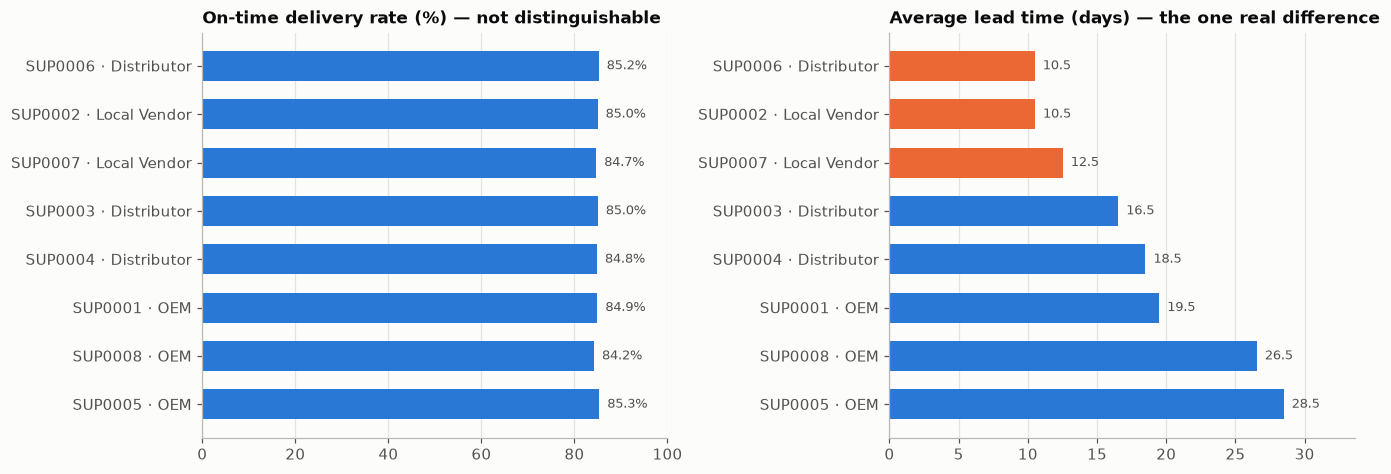

saved chart q8_01_supplier_ontime_vs_lead_time.png


In [25]:
sc_ = sc.sort_values("avg_lead_days").reset_index(drop=True); names = sc_.supplier_id+" · "+sc_.supplier_type
fig, axs = figs(1,2,size=(12.5,4.4))
hbar(axs[0], names, sc_.on_time_pct, "On-time delivery rate (%) — not distinguishable", fmt="{:.1f}%"); axs[0].set_xlim(0,100)
hbar(axs[1], names, sc_.avg_lead_days, "Average lead time (days) — the one real difference", fmt="{:.1f}", color=BLUE, hi=[0,1,2])
savefig(fig, "q8_01_supplier_ontime_vs_lead_time.png")

## 3.3 Q8 — Answer
Delivery outcomes (on-time, delay, lead time) belong to the whole purchase order — lines on one PO share one supplier and one set of dates — so these dimensions are tested **per purchase order** (21,630 received POs), not per line. Testing lines as if they were independent inflates the evidence (on-time p ≈ 0.0001 by line, 0.97 by PO; see `q8_unit_of_analysis_comparison.csv`).

| Dimension | Result | Verdict |
|---|---|---|
| On-time rate | 84.2–85.3% across suppliers; chi-square p = 0.97, Cramér's V = 0.009 | **Not distinguishable — not a basis for selection** |
| Delay | average 0.49–0.55 days per PO; Kruskal-Wallis p = 0.88 | **Not distinguishable — not a basis** |
| PO cancellations (per PO) | 9.4–10.3%; chi-square p = 0.91 | **Not distinguishable — not a basis** |
| Unit cost | index 0.999–1.001 of the product mean; Kruskal-Wallis p ≈ 0.84 (tested per PO line, since cost is a line attribute) | **Not distinguishable — no supplier is cheaper** |
| `reliability_score` | 3, 4 and 5 give the same on-time rate (84.6–85.1%); across the 8 suppliers the correlation with on-time is weakly negative (−0.36, not meaningful with n = 8) | **Does not predict performance — do not use it** |
| **Lead time** | **10.5 to 28.5 days per supplier**, fixed by contract; Kruskal-Wallis p < 1e-300, effect size ε² = 0.93; actual lead time = supplier lead days + delay exactly | **The only real differentiator** |

**Answer.** Suppliers are **not statistically distinguishable** on on-time rate, delay, cancellations, price or reliability score, so the Week-3 statement holds on every dimension tested. They are **not identical**: they differ strongly and consistently on contractual **lead time**, which is a contract term, not an observed performance outcome. Supplier types overlap on lead time (Distributor 10.5–18.5 days, average 15.2; Local Vendor 10.5–12.5, average 11.5; OEM 19.5–28.5, average 24.8), so lead time should be read supplier by supplier, not by type. The only data-supported basis for choosing or consolidating suppliers is therefore lead time: shorter-lead suppliers (SUP0002, SUP0006, SUP0007 at 10.5–12.5 days) would let the business hold less safety stock with no price or reliability difference. Because every product is bought from all 8 suppliers, no supplier is "specialised" (this is why Q9 was closed). **Caveat:** the purchase quantities themselves are suspect (Part 4), so any consolidation decision should wait for Q10.

# Part 4 — Q10: Which side is on the wrong scale — purchases or sales?

Received purchase quantities are ~18× the units sold, and `current_stock` (~107,000) is on a different scale from `max_stock` (~322). **No stock KPI (turnover, cover, stock health, replenishment) can be reported until this is understood.**

**Approach:** (a) measure the gap precisely, (b) test whether it is a unit-of-measure issue, (c) test whether it is product-, time- or branch-specific, (d) see which fields agree with which scale, (e) check how the ledger relates to the purchase and sales files.

## 4.1 Size of the gap

In [26]:
po_units, sold_units = int(rcv.quantity.sum()), int(deliv_l.quantity.sum())
led_in  = int(led.loc[led.movement_type=="IN","quantity"].sum()); led_out = int(led.loc[led.movement_type=="OUT","quantity"].sum())
print(f"PO units received (Received POs) : {po_units:>12,}")
print(f"Ledger IN units                  : {led_in:>12,}")
print(f"Units sold (Delivered orders)    : {sold_units:>12,}")
print(f"Ledger OUT units                 : {led_out:>12,}")
print(f"\nReceived ÷ sold = {po_units/sold_units:.2f}×      Ledger IN ÷ ledger OUT = {led_in/led_out:.2f}×")
check("PO received ÷ units sold = 18.1×", 18.1, round(po_units/sold_units,1), round(po_units/sold_units,1)==18.1)
check("PO units received 22.39M", 22.39, round(po_units/1e6,2), round(po_units/1e6,2)==22.39)
q = pd.DataFrame({"PO lines (received)": rcv.quantity.describe(), "Sales lines (delivered)": deliv_l.quantity.describe()}).round(1)
print("\nQuantity per order line:"); print(q.to_string())
print(f"\nLine-count ratio {len(rcv)/len(deliv_l):.2f}×  ×  quantity-per-line ratio {rcv.quantity.mean()/deliv_l.quantity.mean():.1f}×  =  {len(rcv)/len(deliv_l)*rcv.quantity.mean()/deliv_l.quantity.mean():.1f}×")

PO units received (Received POs) :   22,387,123
Ledger IN units                  :   20,397,795
Units sold (Delivered orders)    :    1,234,939
Ledger OUT units                 :    1,124,832

Received ÷ sold = 18.13×      Ledger IN ÷ ledger OUT = 18.13×

Quantity per order line:
       PO lines (received)  Sales lines (delivered)
count           140,077.00               117,656.00
mean                159.80                    10.50
std                  81.10                     5.80
min                  20.00                     1.00
25%                  90.00                     6.00
50%                 160.00                    10.00
75%                 230.00                    16.00
max                 300.00                    20.00

Line-count ratio 1.19×  ×  quantity-per-line ratio 15.2×  =  18.1×


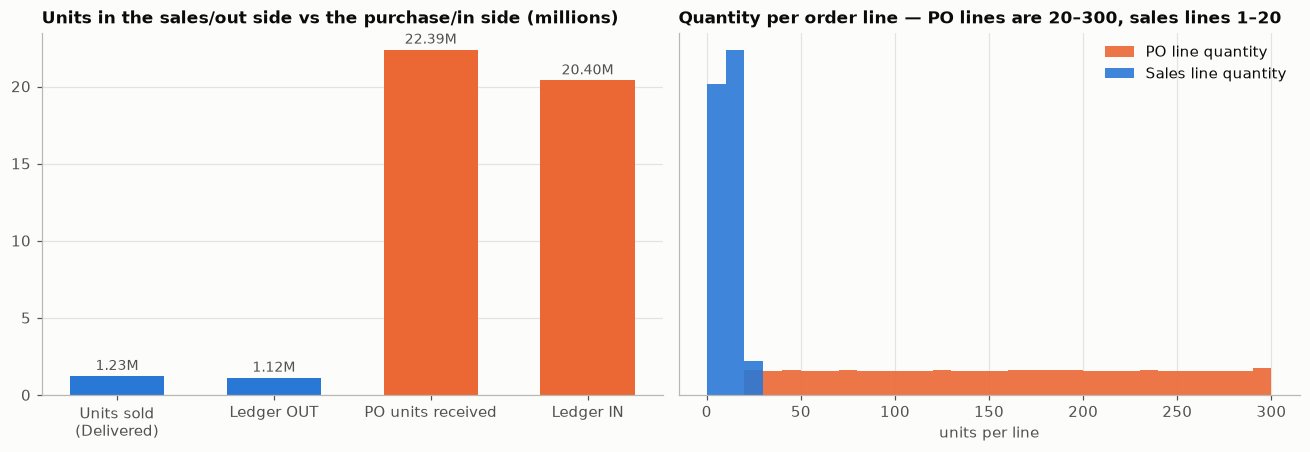

saved chart q10_01_totals_and_line_quantities.png


In [27]:
fig, axs = figs(1,2,size=(12,4.2))
lab = ["Units sold\n(Delivered)","Ledger OUT","PO units received","Ledger IN"]; val = np.array([sold_units, led_out, po_units, led_in])/1e6
axs[0].bar(lab, val, color=[BLUE,BLUE,ORANGE,ORANGE], width=.6); [axs[0].text(i, v+.4, f"{v:.2f}M", ha="center", fontsize=9, color=INK2) for i,v in enumerate(val)]
axs[0].set_title("Units in the sales/out side vs the purchase/in side (millions)"); axs[0].grid(axis="x", visible=False)
bins = np.arange(0,305,10)
axs[1].hist(rcv.quantity, bins=bins, color=ORANGE, alpha=.9, label="PO line quantity", density=True)
axs[1].hist(deliv_l.quantity, bins=bins, color=BLUE, alpha=.9, label="Sales line quantity", density=True)
axs[1].set_title("Quantity per order line — PO lines are 20–300, sales lines 1–20"); axs[1].legend(); axs[1].set_xlabel("units per line"); axs[1].set_yticks([])
savefig(fig, "q10_01_totals_and_line_quantities.png")

## 4.2 Is it a unit-of-measure problem?

By product (30): min 17.4×, median 18.1×, max 19.2×
By unit of measure: {'cartridge': 18.05, 'piece': 18.08, 'set': 18.35}
By received year  : {2019: 17.1, 2020: 17.9, 2021: 18.1, 2022: 18.2, 2023: 18.3, 2024: 18.2}
By product–branch pair (180): min 13.4×, max 25.5×
saved q10_ratio_by_product.csv (30 rows)


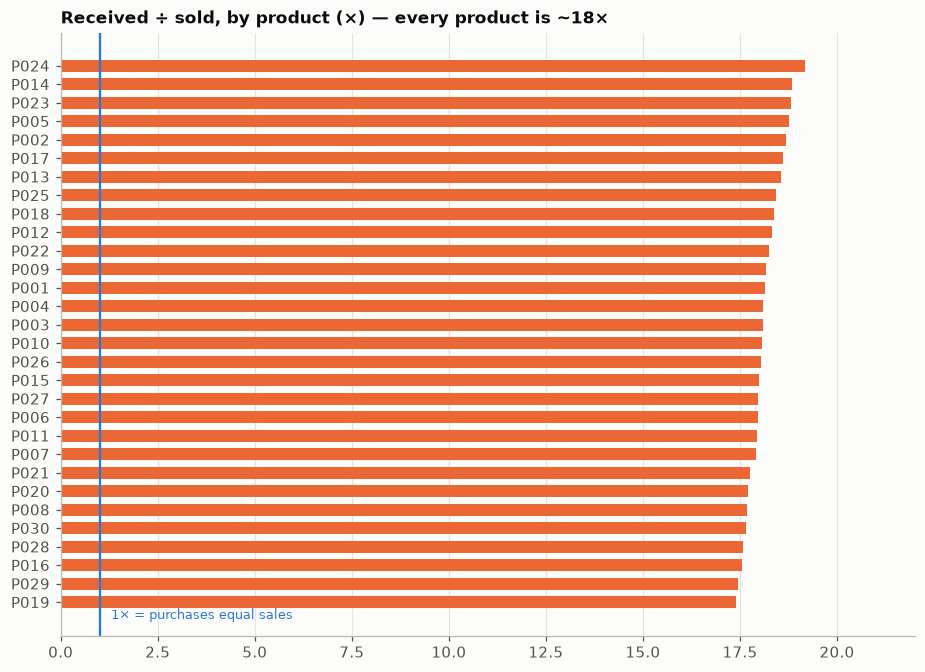

saved chart q10_02_ratio_by_product.png


In [28]:
pp = pd.DataFrame({"po_units": rcv.groupby("product_id").quantity.sum(), "sold_units": deliv_l.groupby("product_id").quantity.sum()})
pp["ratio"] = pp.po_units/pp.sold_units
by_uom  = (rcv.groupby("uom").quantity.sum()/deliv_l.groupby("uom").quantity.sum()).rename("ratio_by_uom")
by_year = (rcv.groupby(rcv.received_date.dt.year).quantity.sum()/deliv_l.groupby("order_year").quantity.sum()).dropna().rename("ratio_by_year")
pair = pd.DataFrame({"po": rcv.groupby(["product_id","branch_id"]).quantity.sum(), "sold": deliv_l.groupby(["product_id","branch_id"]).quantity.sum()}).dropna()
pair["ratio"] = pair.po/pair.sold
print(f"By product (30): min {pp.ratio.min():.1f}×, median {pp.ratio.median():.1f}×, max {pp.ratio.max():.1f}×")
print("By unit of measure:", by_uom.round(2).to_dict()); print("By received year  :", by_year.round(1).to_dict())
print(f"By product–branch pair ({len(pair)}): min {pair.ratio.min():.1f}×, max {pair.ratio.max():.1f}×")
save(pp.reset_index(), "q10_ratio_by_product.csv")
check("gap is the same for every product (17–20×)", "17-20", f"{pp.ratio.min():.1f}-{pp.ratio.max():.1f}", pp.ratio.between(17,20).all())
fig, ax = figs(size=(8.5,6.2)); s_ = pp.ratio.sort_values()
ax.barh(s_.index, s_.values, color=ORANGE, height=.65); ax.axvline(1, color=BLUE, lw=1.5); ax.text(1.3, -.9, "1× = purchases equal sales", color=BLUE, fontsize=8.5)
ax.set_title("Received ÷ sold, by product (×) — every product is ~18×"); ax.grid(axis="y", visible=False); ax.set_xlim(0,22)
savefig(fig, "q10_02_ratio_by_product.png")

**Reading:** the ~18× gap is **the same for every product** (17.4–19.2×), for **every unit of measure** (piece, set, cartridge: ≈18×) and **every year**. A genuine unit mix-up (e.g. cases vs pieces) would differ by UoM or product. This is a **systematic difference in how purchase quantities and sales quantities were generated**, not a product-specific data-entry error. It is a mix of larger lines (PO lines average 160 units, sales lines 10.5 → 15×) and more lines (1.19×).

## 4.3 Which fields agree with which scale?

In [29]:
n_pairs = len(invl); years = 6
sales_pair_month = sold_units/n_pairs/(years*12); po_pair_month = po_units/n_pairs/(years*12)
sc_tab = pd.DataFrame({"units per product–branch pair": [
    sales_pair_month, po_pair_month, invl.max_stock.mean(), invl.reorder_level.mean(), invl.safety_stock.mean(), invl.current_stock.mean()]},
    index=["sold per month","purchased (received) per month","max_stock","reorder_level","safety_stock","current_stock"])
sc_tab["months of sales"] = sc_tab.iloc[:,0]/sales_pair_month
save(sc_tab.reset_index().rename(columns={"index":"measure"}), "q10_scale_comparison.csv")
print(sc_tab.round(1).to_string())
print("\ncurrent_stock vs ledger_latest_balance (mean):", round(invl.current_stock.mean()), "vs", round(invl.ledger_latest_balance.mean()))

saved q10_scale_comparison.csv (6 rows)
                                units per product–branch pair  months of sales
sold per month                                          95.30             1.00
purchased (received) per month                       1,727.40            18.10
max_stock                                              321.80             3.40
reorder_level                                           64.60             0.70
safety_stock                                            45.20             0.50
current_stock                                      107,240.40         1,125.40

current_stock vs ledger_latest_balance (mean): 107240 vs 107256


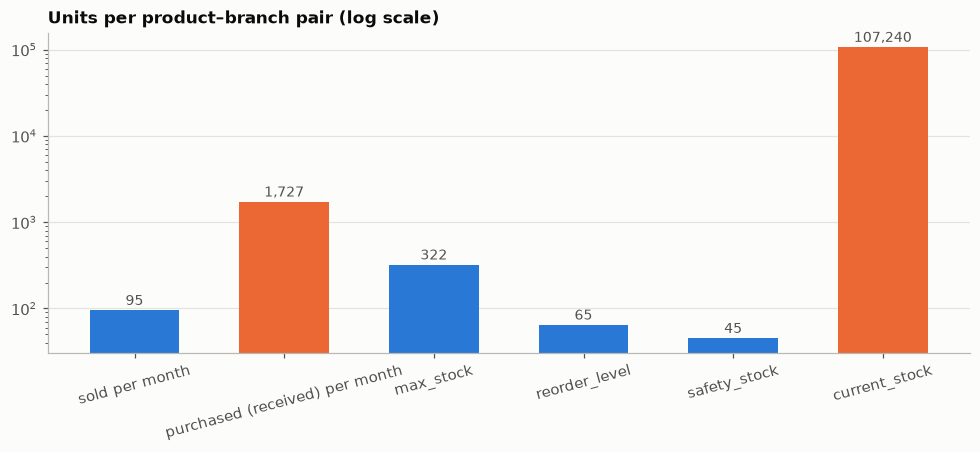

saved chart q10_03_scale_comparison.png


In [30]:
fig, ax = figs(size=(9,4.2)); v = sc_tab.iloc[:,0].values
colors = [BLUE,ORANGE,BLUE,BLUE,BLUE,ORANGE]
ax.bar(sc_tab.index, v, color=colors, width=.6); ax.set_yscale("log")
for i,x_ in enumerate(v): ax.text(i, x_*1.15, f"{x_:,.0f}", ha="center", fontsize=9, color=INK2)
ax.set_title("Units per product–branch pair (log scale)"); ax.grid(axis="x", visible=False); plt.xticks(rotation=15)
savefig(fig, "q10_03_scale_comparison.png")

**Reading:** `max_stock` (≈ 322), `reorder_level` (≈ 65) and `safety_stock` (≈ 45) are sized in line with **monthly sales** (≈ 95 units per product–branch pair): max stock ≈ 3.4 months of demand, reorder level ≈ 3 weeks. Purchases are ≈ 1,700 units per pair per month — 5.4× `max_stock` arriving every month — and `current_stock` (≈ 107,000) is simply the **ledger balance**, which is built from those purchases. Three independent fields plus the sales data agree on the small scale; only the purchase quantities (and what is derived from them) are the outlier.

## 4.4 How the ledger relates to purchases and sales

In [31]:
cov_tab = pd.DataFrame({"source rows": [len(rcv), (led.movement_type=="IN").sum(), len(deliv_l), (led.movement_type=="OUT").sum()],
                        "units": [po_units, led_in, sold_units, led_out]},
                       index=["PO lines received","Ledger IN rows","Delivered sales lines","Ledger OUT rows"])
print(cov_tab.to_string())
print(f"\nLedger IN rows cover {(led.movement_type=='IN').sum()/len(rcv)*100:.1f}% of received PO lines; OUT rows cover {(led.movement_type=='OUT').sum()/len(deliv_l)*100:.1f}% of delivered sales lines.")
print("Ledger IN reference types:", led.loc[led.movement_type=="IN","reference_type"].value_counts().to_dict(), "| OUT:", led.loc[led.movement_type=="OUT","reference_type"].value_counts().to_dict())
# a naive uniform rescale of purchases does NOT give valid stock
k = po_units/sold_units
wi = invl.opening_stock + invl.total_in_qty/k - invl.total_out_qty
ok = ((wi>=0)&(wi<=invl.max_stock)).mean()*100
print(f"\nWhat-if: scale every purchase down by {k:.1f}× → only {ok:.0f}% of the 180 pairs end between 0 and max_stock.")

                       source rows     units
PO lines received           140077  22387123
Ledger IN rows              127611  20397795
Delivered sales lines       117656   1234939
Ledger OUT rows             107165   1124832

Ledger IN rows cover 91.1% of received PO lines; OUT rows cover 91.1% of delivered sales lines.
Ledger IN reference types: {'PO': 127611} | OUT: {'SO': 107165}

What-if: scale every purchase down by 18.1× → only 8% of the 180 pairs end between 0 and max_stock.


**Reading:** the ledger faithfully mirrors the two source files — it inherits the purchase scale on the IN side and the sales scale on the OUT side — and covers ~91% of the received PO lines and of the delivered sales lines. A **uniform rescale does not repair it**: dividing every purchase by 18.1 leaves most product–branch pairs outside 0…`max_stock`, because the ratio itself varies from 13× to 26× across pairs. The inconsistency is therefore not a simple unit factor.

## 4.5 Q10 — Answer
| Finding | Evidence |
|---|---|
| **The gap is 18.1×:** 22.39M units received vs 1.23M sold. | 4.1 |
| **It is not a unit-of-measure issue and not product-specific:** the same ~18× for every product (17.4–19.2×), every UoM and every year. | 4.2 |
| **The purchase side is the outlier.** Sales volume, `max_stock`, `reorder_level` and `safety_stock` all agree on the small scale; purchase quantities (and the ledger / `current_stock` built from them) do not. | 4.3 |
| **There is no clean fix inside the data.** A uniform rescale leaves most pairs invalid; the ledger inherits both scales. | 4.4 |
| **Impact:** stock turnover, days of cover, stock-health classes and replenishment policy **cannot be reported** (Q11 is blocked). | |
| **Recommendation:** treat PO quantities (and `current_stock`) as unreliable; raise with the data owner whether PO quantities were generated on a different scale; until answered, report sales-side KPIs only and keep stock KPIs out of the submission. | |

# Part 5 — Summary and validation

| Q | Answer in one line |
|---|---|
| **Q1** | Price cannot be tested (one price list). The 2023→2024 fall of ₹146.7M is about 57% fewer delivered orders (fewer placed + more cancellations) and about 43% lower value per order (mostly product mix: Engine and Hydraulic down, but mix and the 2024 step are not distinguishable from noise). |
| **Q2** | Concentration is customer-base size: revenue per customer is the same in every region (~₹45M); Central and North East have 11 customers each and no branch. Growth is an acquisition question. |
| **Q8** | Suppliers are not statistically distinguishable on on-time rate, delay, cancellations, price and reliability score (tested per purchase order); the only real difference is contractual lead time (10.5–28.5 days). |
| **Q10** | Purchases are 18.1× sales for every product, UoM and year; the purchase side is the outlier and stock KPIs must wait for the data owner. |

In [32]:
vr = pd.DataFrame(checks, columns=["Check_Item","Expected","Actual","Status"])
vr.to_csv("validation_report_week04.csv", index=False)
print(vr.to_string(index=False)); print(f"\n{(vr.Status=='PASS').sum()} / {len(vr)} checks passed")
assert (vr.Status=="PASS").all()

                                                                                    Check_Item Expected                Actual Status
                                                                       sales rows (line grain)   130402                130402   PASS
                                                                                 unique orders    20000                 20000   PASS
                                                                          PO rows (line grain)   155495                155495   PASS
                                                                               inventory pairs      180                   180   PASS
                                                                                   ledger rows   237230                237230   PASS
                                                          net revenue matches Week 3 (₹22.96B)    22.96                 22.96   PASS
                                                              yearly 